# Ideal-spectrum RV recovery

<span style="color:red">The HISPEC DRP is in active development. Please submit issues and suggestions on the [GitHub](https://github.com/oirlab/HISPEC_DRP).</span>

From the rest-frame **BT-Settl lte040** (4000 K) template, we simulate a
**native** BSPEC L2 (Doppler paint, no HDF LSF) then recover its injected RV
with the packaged full-band `*.ccfopt.delta.mas` line mask and
`recover_stellar_rv` (same line-by-line `ccf_line_mask` path as
`build_ccfopt_mask`). That packaged mask is the default
`paired_line_mask_path_for_template(..., mask_style="ccfopt.delta")` product
(~887 lines). In this example, this is done for injected RVs from 0-50 km/s
in steps of 10 km/s and the injected versus recovered RVs are plotted at the
end, including the recovered RV uncertainty and residual.

The packaged `lte040...lsf.ccfopt.delta.mas` is a two-order smoke file and is
not used here. For an LSF-matched closed loop, set `APPLY_LSF = True` and
pass a full-band `*.lsf.ccfopt.delta.mas` from `ensure_lsf_ccfopt_mask`.


In [1]:
from pathlib import Path

import hispecdrp

print(f"hispecdrp {hispecdrp.__version__} @ {hispecdrp.__file__}")

OUT = Path("/Users/ckilpatrick/ideal_spectrum_rv_recovery")
OUT.mkdir(parents=True, exist_ok=True)
print("output:", OUT.resolve())


hispecdrp 0.0.post957+gf8dfcb577.d20260828 @ /Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/__init__.py
output: /Users/ckilpatrick/ideal_spectrum_rv_recovery


## 1. Configure template and mask

Packaged lte040 template and the packaged full-band **native**
`*.ccfopt.delta.mas` line mask (default `ccfopt.delta` pairing). Recovery uses
ccfopt line-by-line defaults on the full BSPEC echelle range.


In [2]:
from hispecdrp.utils.line_mask_utils import (
    paired_line_mask_path_for_template,
    read_mask_generation_meta,
)

FIBER = 1
BULK_RV_KM_S = [0.0, 10.0, 20.0, 30.0, 40.0, 50.0]
TEMPLATE = "lte040.0-4.5-0.0a+0.0.BT-Settl.spec.7.h5"
APPLY_LSF = False
MASK_PATH = paired_line_mask_path_for_template(TEMPLATE, mask_style="ccfopt.delta")
meta = read_mask_generation_meta(MASK_PATH) or {}
print(f"mask: {MASK_PATH}")
print(
    f"n_lines={meta.get('n_lines')}  n_seed={meta.get('n_seed_lines')}  "
    f"n_drop={meta.get('n_dropped_lines')}"
)


mask: /Users/ckilpatrick/ideal_spectrum_rv_recovery/lte040.0-4.5-0.0a+0.0.BT-Settl.spec.7.lsf.ccfopt.delta.mas
n_lines=869  n_seed=1066  n_drop=197


## 2. Inject, recover, and collate

For each bulk shift, `build_l2` injects the template into a native BSPEC L2
(`apply_lsf=False`), then `recover_stellar_rv` runs the same line-by-line
`ccf_line_mask` path as `build_ccfopt_mask` (`IDEAL_SPECTRUM_STELLAR_RV_KW`)
with the packaged `*.ccfopt.delta.mas` mask.


In [3]:
import numpy as np

from hispecdrp.simulations.spectra import build_l2, recover_stellar_rv

hdr = (
    f"{'bulk_km/s':>10}  {'injected_m/s':>14}  {'recovered_m/s':>16}  "
    f"{'rv_err_m/s':>12}  {'bias_m/s':>12}  {'bias_mm/s':>10}"
)
print(hdr)
print("-" * len(hdr))

inj_m_s = []
rec_m_s = []
err_m_s = []

for bulk in BULK_RV_KM_S:
    l2 = build_l2(
        bulk,
        template=TEMPLATE,
        fiber=FIBER,
        apply_lsf=APPLY_LSF,
    )
    inj, rec, err = recover_stellar_rv(
        l2,
        bulk,
        template=TEMPLATE,
        mask_path=str(MASK_PATH),
        spectrograph="BSPEC",
        fiber=FIBER,
    )
    bias = rec - inj
    inj_m_s.append(inj)
    rec_m_s.append(rec)
    err_m_s.append(err)
    print(
        f"{bulk:10.1f}  {inj:14.4f}  {rec:16.6f}  {err:12.6f}  "
        f"{bias:12.6e}  {bias * 1e3:10.4f}"
    )

inj_m_s = np.asarray(inj_m_s, dtype=float)
rec_m_s = np.asarray(rec_m_s, dtype=float)
err_m_s = np.asarray(err_m_s, dtype=float)
bias_m_s = rec_m_s - inj_m_s
max_abs = float(np.max(np.abs(bias_m_s)))
rms = float(np.sqrt(np.mean(bias_m_s**2)))
d_bias = bias_m_s - bias_m_s[0]
max_d = float(np.max(np.abs(d_bias[1:])))
print()
print(f"max|bias| = {max_abs:.6e} m/s ({max_abs * 1e3:.4f} mm/s)")
print(f"rms bias  = {rms:.6e} m/s ({rms * 1e3:.4f} mm/s)")
print(f"max|differential bias| (vs RV=0) = {max_d:.6e} m/s ({max_d * 1e3:.4f} mm/s)")


 bulk_km/s    injected_m/s     recovered_m/s    rv_err_m/s      bias_m/s   bias_mm/s
------------------------------------------------------------------------------------
       0.0          0.0000          0.000015      0.000345  1.509011e-05      0.0151
      10.0      10000.0000       9999.918512      0.073784  -8.148800e-02    -81.4880
      20.0      20000.0000      19999.917130      0.072865  -8.286968e-02    -82.8697
      30.0      30000.0000      29999.977820      0.074722  -2.218040e-02    -22.1804
      40.0      40000.0000      40000.108289      0.072649  1.082888e-01    108.2888
      50.0      50000.0000      49999.895982      0.075064  -1.040177e-01   -104.0177

max|bias| = 1.082888e-01 m/s (108.2888 mm/s)
rms bias  = 7.804462e-02 m/s (78.0446 mm/s)
max|differential bias| (vs RV=0) = 1.082737e-01 m/s (108.2737 mm/s)


## 3. Plot

The lower panel shows residuals from the 1:1 line (recovered minus injected) on
a zoomed scale so bias can be compared with the reported `RV_ERR` bars.


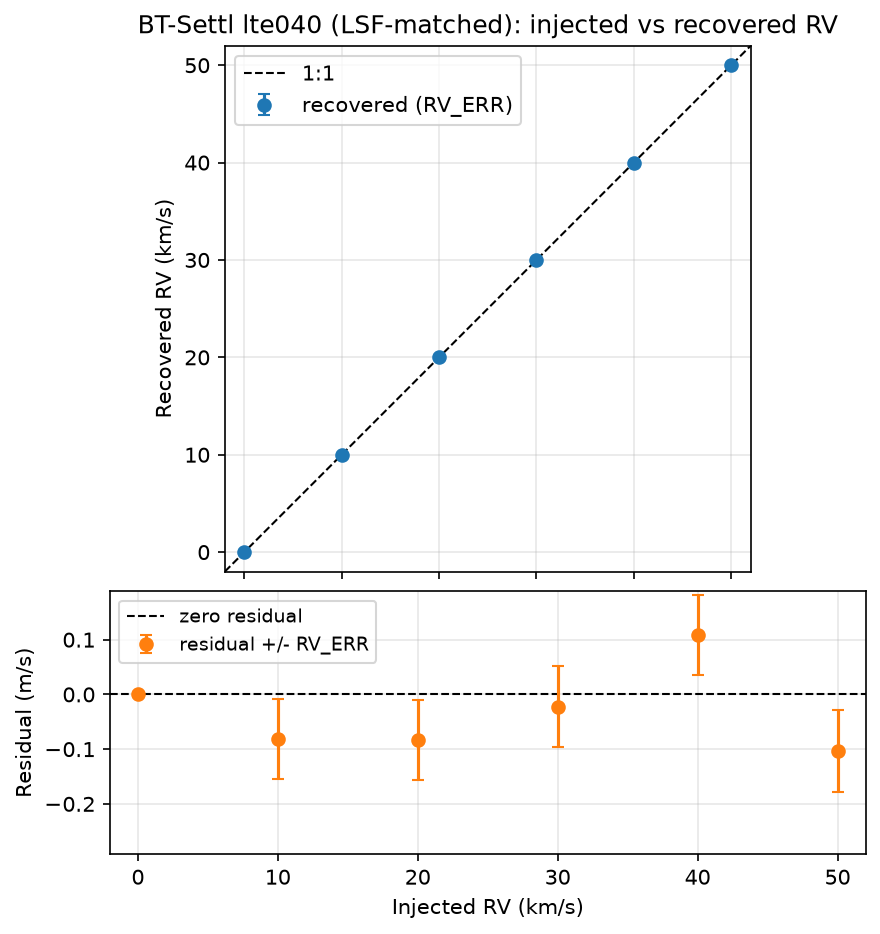

wrote /Users/ckilpatrick/ideal_spectrum_rv_recovery/lte040_lsf_simulated_vs_recovered_rv.png


In [4]:
from hispecdrp.simulations.plotting import plot_ideal_spectrum_rv_recovery

summary = plot_ideal_spectrum_rv_recovery(
    inj_m_s,
    rec_m_s,
    err_m_s,
    title="BT-Settl lte040 (native): injected vs recovered RV",
    out_path=OUT / "lte040_simulated_vs_recovered_rv.png",
)
if summary.get("out_path"):
    print("wrote", summary["out_path"])
